# SuperNeuroABM Tutorial 02: What Each Soma and Synapse Does

Tutorials 00 and 01 built networks. This one looks at the parts one at a time: every built-in
soma breed is driven with a simple input and its state is plotted, then the synapse is taken
apart (weight, sign, channel time constant), and the six built-in learning rules are compared
on one spike pairing.

Everything runs on the packaged `component_base_config.yaml`. The recipe is the same in every
section:

1. create a model with `enable_internal_states_tracking=True` so the per-tick state is kept;
2. create one soma (or a few) and, where a synapse is needed, one external `delivery_synapse`
   (`pre_soma_id=-1`) that we drive with `add_spike_list`;
3. `setup()`, `simulate()`, and read `get_internal_states_history(soma)`.

A word on **how input reaches a soma**, since every plot below shows it: a synapse delivers
`spike * weight * scale` into one *channel* of its post soma's inbox the moment its presynaptic
neuron fires. The soma owns the synaptic time constants: channel `c` is filtered with
`tau_syn_c` into the state `I_syn_c`, and the sum is what the membrane integrates. A channel
whose time constant equals `dt` is a one-tick pulse. Each soma records that summed current in
its history, which is why the plots can show both the membrane and what drove it.

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from pathlib import Path
import yaml

import superneuroabm
from superneuroabm.model import NeuromorphicModel

CONFIG = yaml.safe_load((Path(superneuroabm.__file__).parent / "component_base_config.yaml").read_text())
print("soma breeds:", list(CONFIG["soma"]))
print("synapse breeds:", list(CONFIG["synapse"]))
print("learning rules:", list(CONFIG["learning_rule"]))

soma breeds: ['lif_soma', 'izh_soma', 'adex_soma', 'hg_lif_soma', 'lif_soma_adaptive_thr']
synapse breeds: ['delivery_synapse']
learning rules: ['exp_pair_wise_stdp', 'three_bit_exp_pair_wise_stdp', 'exp_pair_wise_stdp_bounded', 'memristive_exp_pair_wise_stdp', 'triplet_stdp', 'suppression_stdp']


In [2]:
def run_soma(breed, config_name, ticks, overrides=None, spikes=None, weight=14.0, dt=None,
             channel=0, soma_overrides_extra=None):
    """One soma of `breed`/`config_name`, optionally one external synapse driven with
    `spikes` (list of ticks). Returns (spike_ticks, history array, model)."""
    model = NeuromorphicModel(enable_internal_states_tracking=True)
    if dt is not None:
        model.set_global_property_value("dt", dt)
    soma = model.create_soma(breed=breed, config_name=config_name, overrides=overrides)
    syn = None
    if spikes:
        syn = model.create_synapse(breed="delivery_synapse", pre_soma_id=-1, post_soma_id=soma,
                                   config_name="config_0",
                                   overrides={"hyperparameters": {"weight": weight, "channel": channel}})
    model.setup()
    if spikes:
        model.add_spike_list(syn, [[int(t), 1.0] for t in spikes])
    model.simulate(ticks=ticks)
    hist = np.array(model.get_internal_states_history(soma), dtype=np.float64)
    return model.get_spike_times(soma), hist, model


def plot_rows(rows, title, dt=1e-3):
    """rows: list of (label, ylabel, trace, spike_ticks). One panel per row, shared time axis."""
    fig, axes = plt.subplots(len(rows), 1, figsize=(11, 2.4 * len(rows)), sharex=True)
    axes = np.atleast_1d(axes)
    for ax, (label, ylabel, trace, spike_ticks) in zip(axes, rows):
        t = np.arange(len(trace)) * dt * 1e3
        ax.plot(t, trace, lw=1.2)
        for s in spike_ticks:
            ax.axvline(s * dt * 1e3, color="r", alpha=0.25, lw=1)
        ax.set_ylabel(ylabel)
        ax.set_title(label, loc="left", fontsize=10)
        ax.grid(alpha=0.3)
    axes[-1].set_xlabel("time (ms)")
    fig.suptitle(title)
    plt.tight_layout()
    plt.show()

## 1. `lif_soma` — leaky integrate-and-fire

The membrane charges towards `vrest` with time constant `R*C`, integrates the synaptic current,
fires at `vthr`, resets to `vreset` and ignores further spiking for `tref`. The default
`config_0` has `vrest = vreset = -60 mV`, `vthr = -45 mV`, `tref = 5 ms`.

Below: a burst of input spikes, then a pause, then a second burst. The lower panel is the
synaptic current the soma recorded (`I_syn`, history column 3): each input spike adds the
weight, and the current decays with `tau_syn_0 = 10 ms`.

lif_soma spikes at ticks: [7, 13, 18, 23, 29, 34, 40, 61, 66, 72, 77, 83, 90]


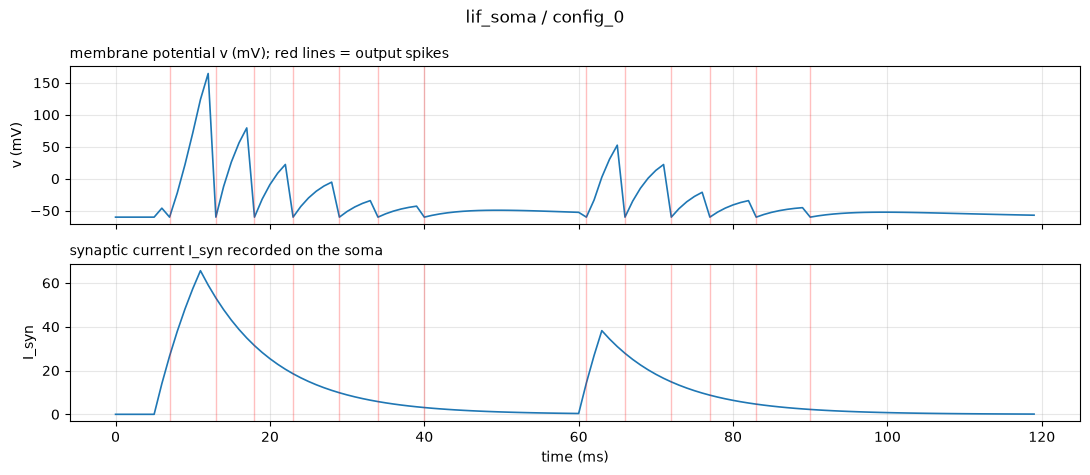

In [3]:
drive = [5, 6, 7, 8, 9, 10, 60, 61, 62]
spikes, hist, _ = run_soma("lif_soma", "config_0", ticks=120, spikes=drive)
print("lif_soma spikes at ticks:", spikes)
plot_rows([
    ("membrane potential v (mV); red lines = output spikes", "v (mV)", hist[:, 0], spikes),
    ("synaptic current I_syn recorded on the soma", "I_syn", hist[:, 3], spikes),
], "lif_soma / config_0")

Notice the refractory period: after each spike the membrane does not move for 5 ticks even
though input keeps arriving (`tref_allows_integration: 1` in the config means it *integrates*
during the refractory period but cannot fire; set it to 0 to freeze the membrane instead).

## 2. `lif_soma_adaptive_thr` — LIF with an adaptive threshold

Same membrane, but the threshold is a state variable: it jumps by `delta_thr` at every spike and
relaxes back to `vthr_initial` with `tau_decay_thr`. A neuron that has just fired a lot becomes
harder to fire, a simple form of homeostasis. The threshold is history column 3.

adaptive-threshold spikes at ticks: [7, 13, 18, 23, 29, 34, 40, 45, 51, 56, 62, 68, 74, 80, 86, 92, 98, 104]


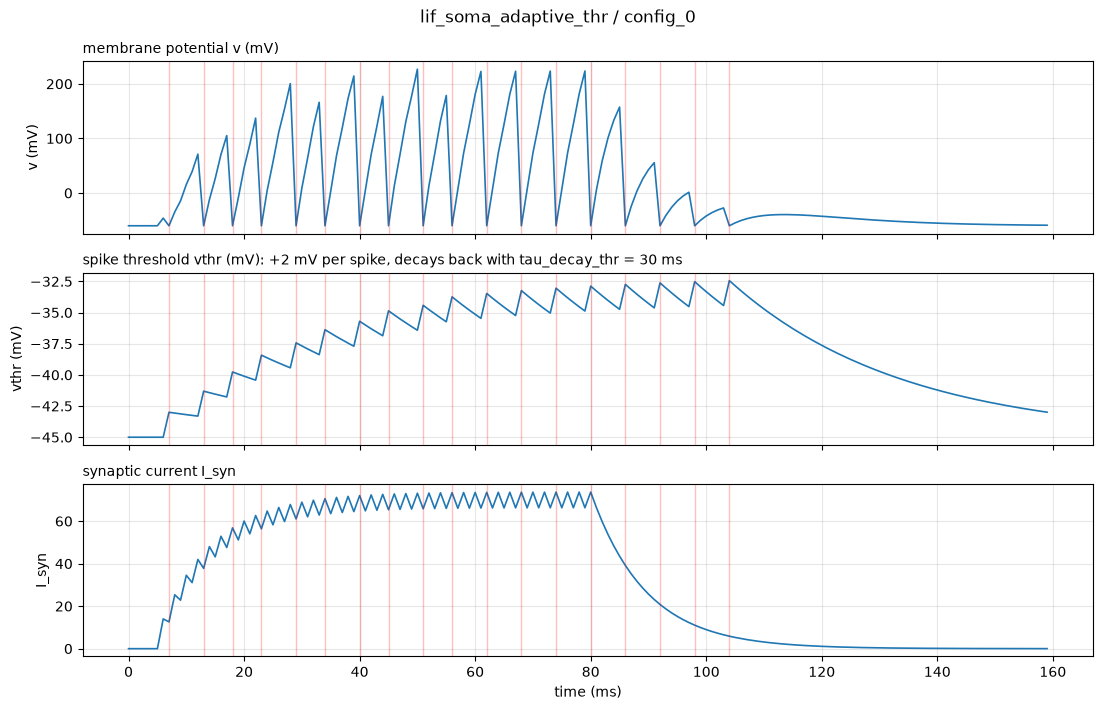

In [4]:
drive = list(range(5, 80, 2))
spikes, hist, _ = run_soma("lif_soma_adaptive_thr", "config_0", ticks=160, spikes=drive,
                           overrides={"hyperparameters": {"delta_thr": 2.0}})
print("adaptive-threshold spikes at ticks:", spikes)
plot_rows([
    ("membrane potential v (mV)", "v (mV)", hist[:, 0], spikes),
    ("spike threshold vthr (mV): +2 mV per spike, decays back with tau_decay_thr = 30 ms", "vthr (mV)", hist[:, 3], spikes),
    ("synaptic current I_syn", "I_syn", hist[:, 4], spikes),
], "lif_soma_adaptive_thr / config_0")

## 3. `izh_soma` — the Izhikevich model, 20 firing patterns

`dv/dt = 0.04 v² + 5 v + 140 − u + I`, `du/dt = a (b v − u)`, reset `v ← c`, `u ← u + d`.
Four parameters, and the packaged config carries the twenty panels of Izhikevich (2004)
figure 1 as `config_0` … `config_19`. Each config's commented `stimulus` line names the input
current of the panel; here it is passed as the constant `I_in`.

The paper integrates with a 0.25 ms step and the model is written in milliseconds, so this
section sets `dt` to the panel's step. `dt` is a global property of the model
(`set_global_property_value("dt", ...)`); the synaptic time constants are in seconds, so they
do not change meaning when `dt` does.

A tonic spiking                  spikes: 13
B phasic spiking                 spikes: 1


C tonic bursting                 spikes: 40
D phasic bursting                spikes: 5


F spike-frequency adaptation     spikes: 14
I spike latency                  spikes: 6


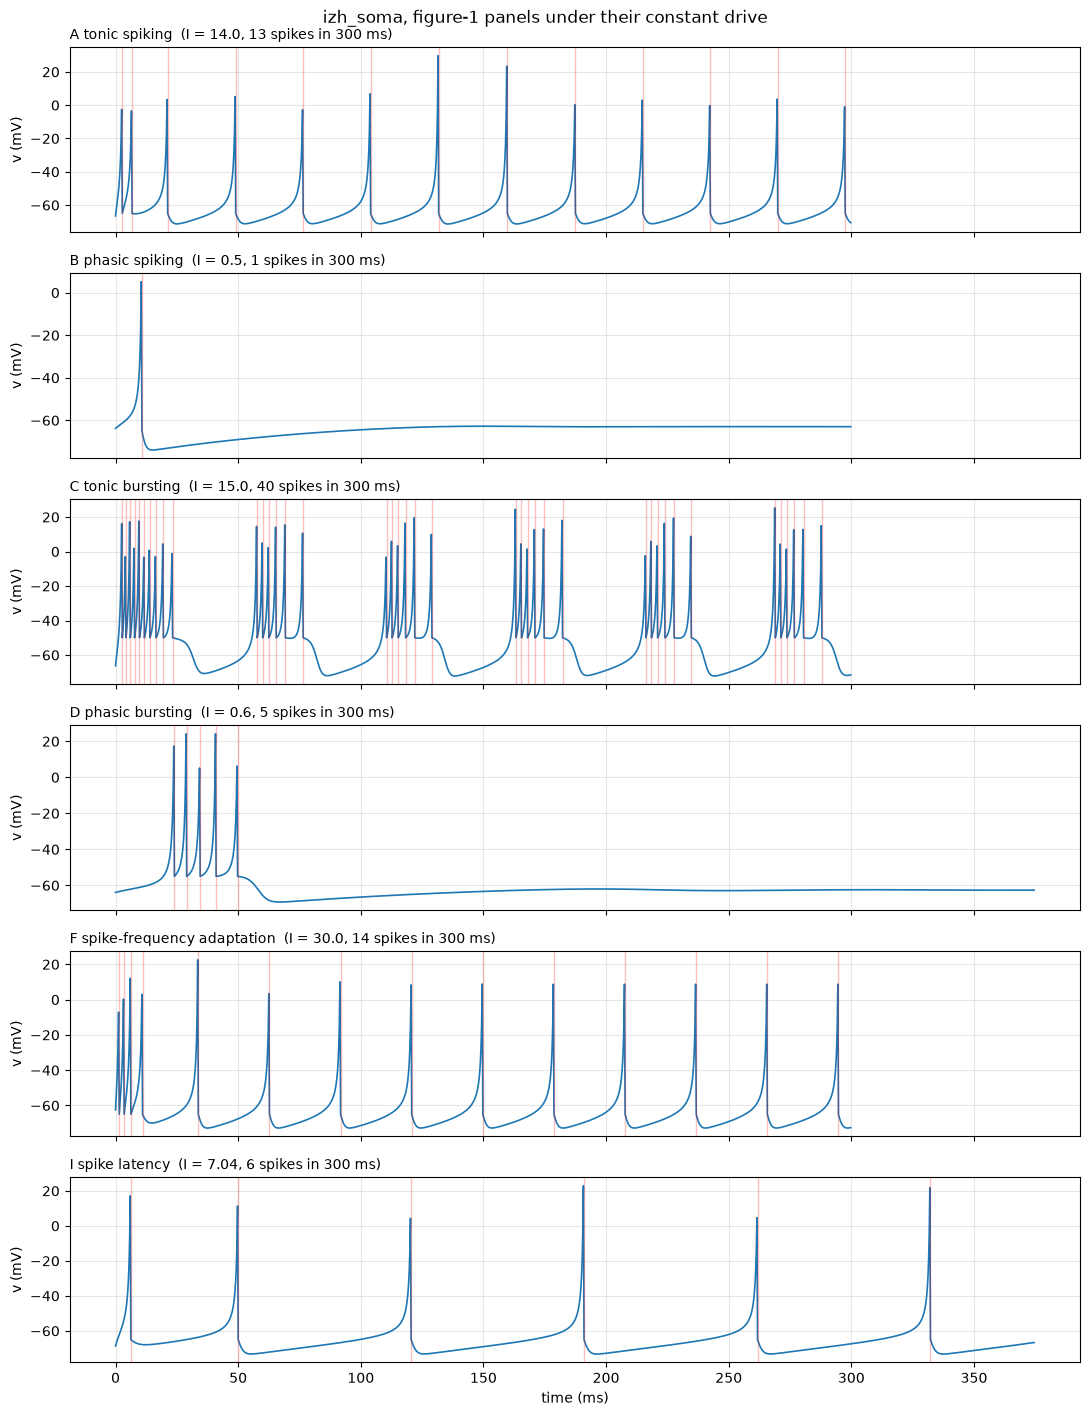

In [5]:
panels = [
    ("config_0", "A tonic spiking", 14.0),
    ("config_1", "B phasic spiking", 0.5),
    ("config_2", "C tonic bursting", 15.0),
    ("config_3", "D phasic bursting", 0.6),
    ("config_5", "F spike-frequency adaptation", 30.0),
    ("config_8", "I spike latency", 7.04),
]
rows = []
for cfg, label, I in panels:
    dt_s = CONFIG["soma"]["izh_soma"][cfg]["hyperparameters"]["dt_s"]
    spikes, hist, _ = run_soma("izh_soma", cfg, ticks=int(0.3 / dt_s), dt=dt_s,
                               overrides={"hyperparameters": {"I_in": I}})
    rows.append((f"{label}  (I = {I}, {len(spikes)} spikes in 300 ms)", "v (mV)", hist[:, 0], spikes))
    print(f"{label:32s} spikes: {len(spikes)}")
plot_rows(rows, "izh_soma, figure-1 panels under their constant drive", dt=2.5e-4)

The panel drives in the paper are *steps* that start a few milliseconds in and some are
ramps or pulses; passing a constant `I_in` from tick 0 reproduces the steady behaviour
(tonic, bursting, adaptation) and the phasic panels show their single response at the start.
To reproduce a panel exactly, inject the paper's waveform through an external synapse
instead: with `tau_syn_0 = dt` every delivered spike value is a one-tick current.

## 4. `adex_soma` — adaptive exponential integrate-and-fire

`C dV/dt = −gL (V − E_L) + gL Δ_T exp((V − V_T)/Δ_T) − w + I`, `τ_w dw/dt = a (V − E_L) − w`;
the exponential term makes the spike upswing, `w` is an adaptation current, and `b` is how much
it jumps per spike. Units are mV, pA and ms. The seven packaged configs are the firing patterns
of *Neuronal Dynamics* table 6.1, each with a 65 pA step (25 pA for delayed spiking).

tonic spiking        spikes: 5
adapting             spikes: 12


initial bursting     spikes: 12
regular bursting     spikes: 24


transient spiking    spikes: 6
delayed spiking      spikes: 2


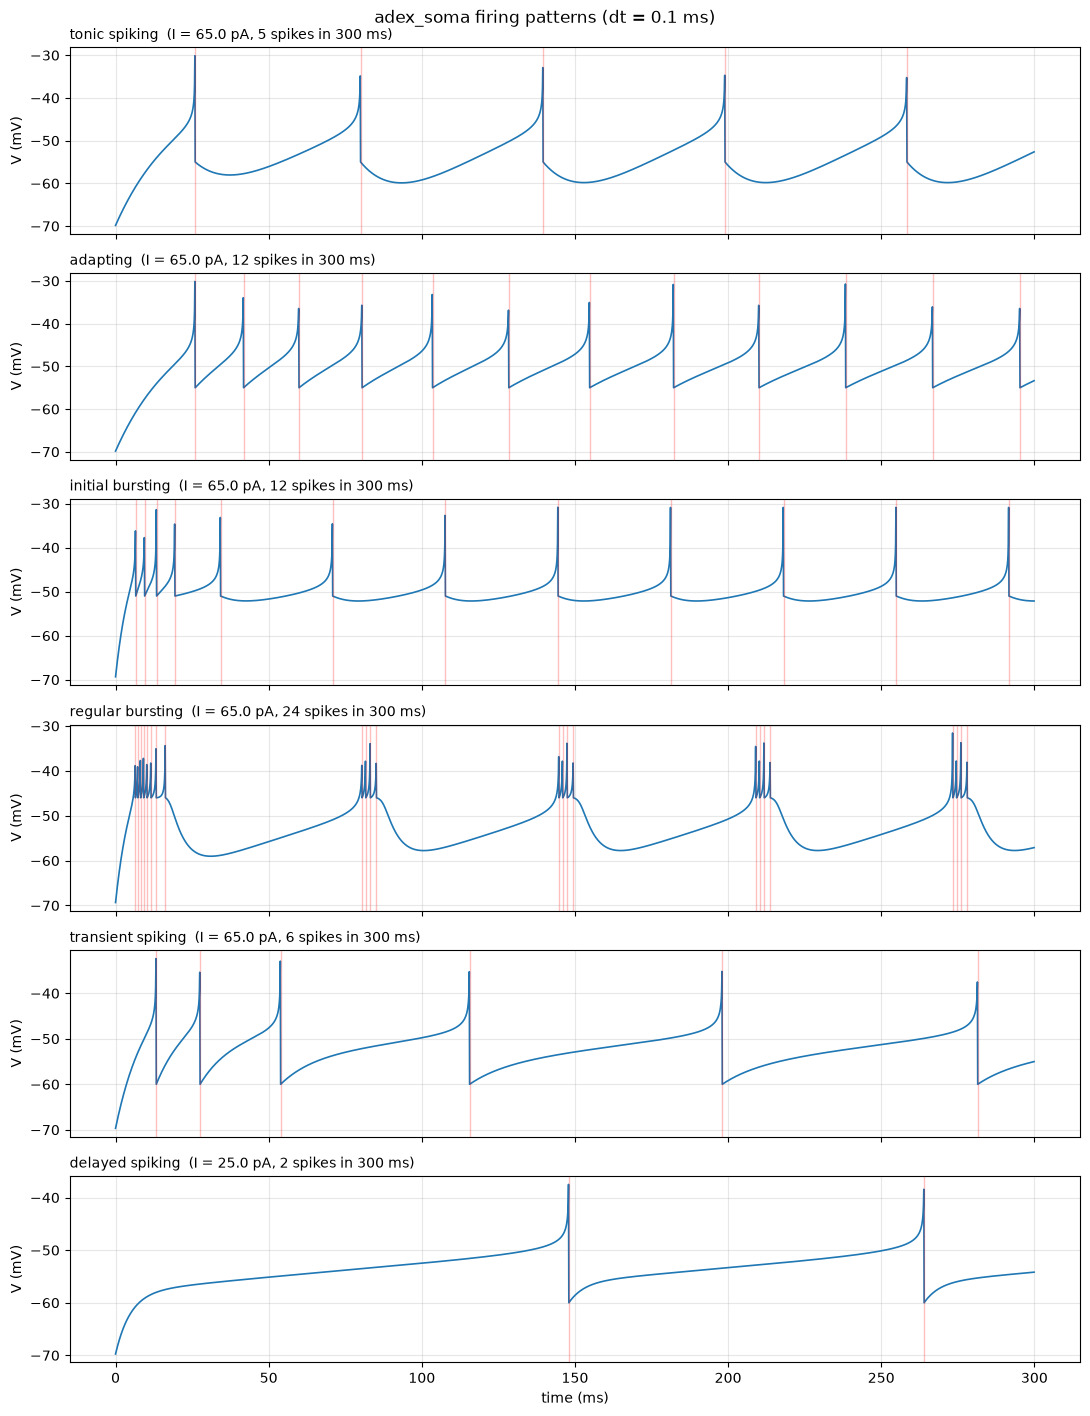

In [6]:
patterns = [
    ("config_0", "tonic spiking", 65.0),
    ("config_1", "adapting", 65.0),
    ("config_2", "initial bursting", 65.0),
    ("config_3", "regular bursting", 65.0),
    ("config_5", "transient spiking", 65.0),
    ("config_6", "delayed spiking", 25.0),
]
rows = []
for cfg, label, I in patterns:
    spikes, hist, _ = run_soma("adex_soma", cfg, ticks=3000, dt=1e-4,
                               overrides={"hyperparameters": {"I_in": I}})
    rows.append((f"{label}  (I = {I} pA, {len(spikes)} spikes in 300 ms)", "V (mV)", hist[:, 0], spikes))
    print(f"{label:20s} spikes: {len(spikes)}")
plot_rows(rows, "adex_soma firing patterns (dt = 0.1 ms)", dt=1e-4)

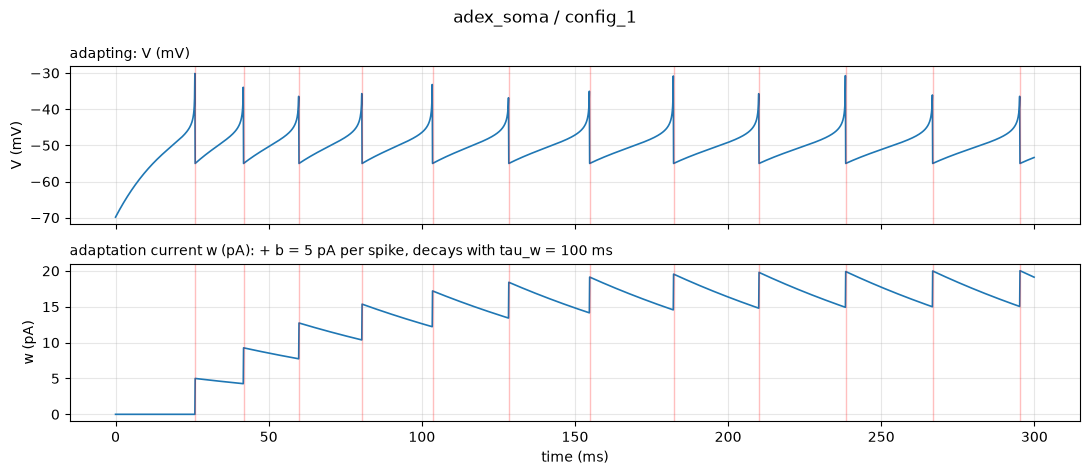

In [7]:
# The adaptation current w is the second state variable: watch it ratchet up by b per spike
spikes, hist, _ = run_soma("adex_soma", "config_1", ticks=3000, dt=1e-4,
                           overrides={"hyperparameters": {"I_in": 65.0}})
plot_rows([
    ("adapting: V (mV)", "V (mV)", hist[:, 0], spikes),
    ("adaptation current w (pA): + b = 5 pA per spike, decays with tau_w = 100 ms", "w (pA)", hist[:, 1], spikes),
], "adex_soma / config_1", dt=1e-4)

## 5. `hg_lif_soma` — the Hathway-Goodman three-variable LIF

The neuron of the Masquelier et al. (2008) replication: an exactly integrated LIF with an
afterhyperpolarisation variable `a` that is set to `deltaa` at a spike and pulls the membrane
down (`A < 0`) while it decays with `taus`. Threshold `T`, the membrane jumps to `2T` at a
spike. The summed EPSP `x` is history column 4.

hg_lif_soma spikes at ticks: [15, 36, 57, 78, 99, 120]


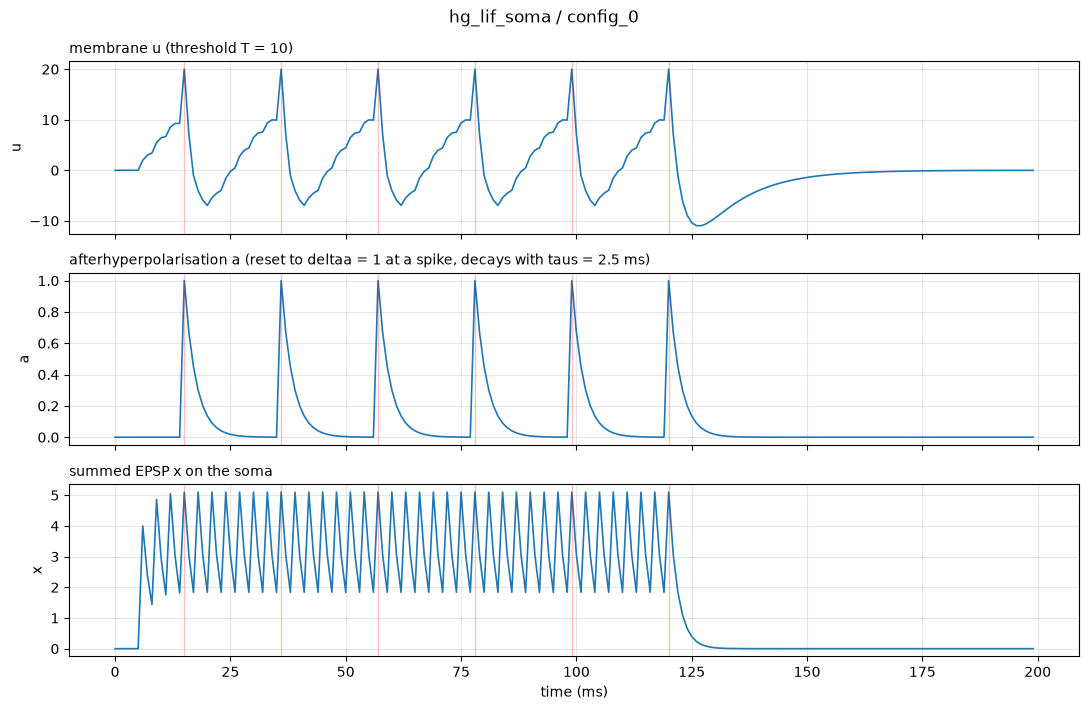

In [8]:
drive = list(range(5, 120, 3))
spikes, hist, _ = run_soma("hg_lif_soma", "config_0", ticks=200, spikes=drive, weight=4.0)
print("hg_lif_soma spikes at ticks:", spikes)
plot_rows([
    ("membrane u (threshold T = 10)", "u", hist[:, 0], spikes),
    ("afterhyperpolarisation a (reset to deltaa = 1 at a spike, decays with taus = 2.5 ms)", "a", hist[:, 3], spikes),
    ("summed EPSP x on the soma", "x", hist[:, 4], spikes),
], "hg_lif_soma / config_0")

## 6. The synapse: `delivery_synapse`

There is one synapse kind. It carries a **weight**, a **scale**, a **channel**, and (if you attach
one) a learning rule. When its presynaptic neuron fires it deposits `spike * weight * scale` into
channel `channel` of the post soma's inbox and is done; the time course of that input is the
soma's business. Three things to see:

1. **weight** sets the amplitude, and a **negative weight is inhibition** (same synapse kind);
2. **channel** selects which of the soma's time constants filters the input — here channel 0 is
   `tau_syn_0 = 10 ms` and channel 1 is set to `tau_syn_1 = 1 ms = dt`, a one-tick pulse;
3. the same spike train through a slow and a fast channel drives the membrane differently.

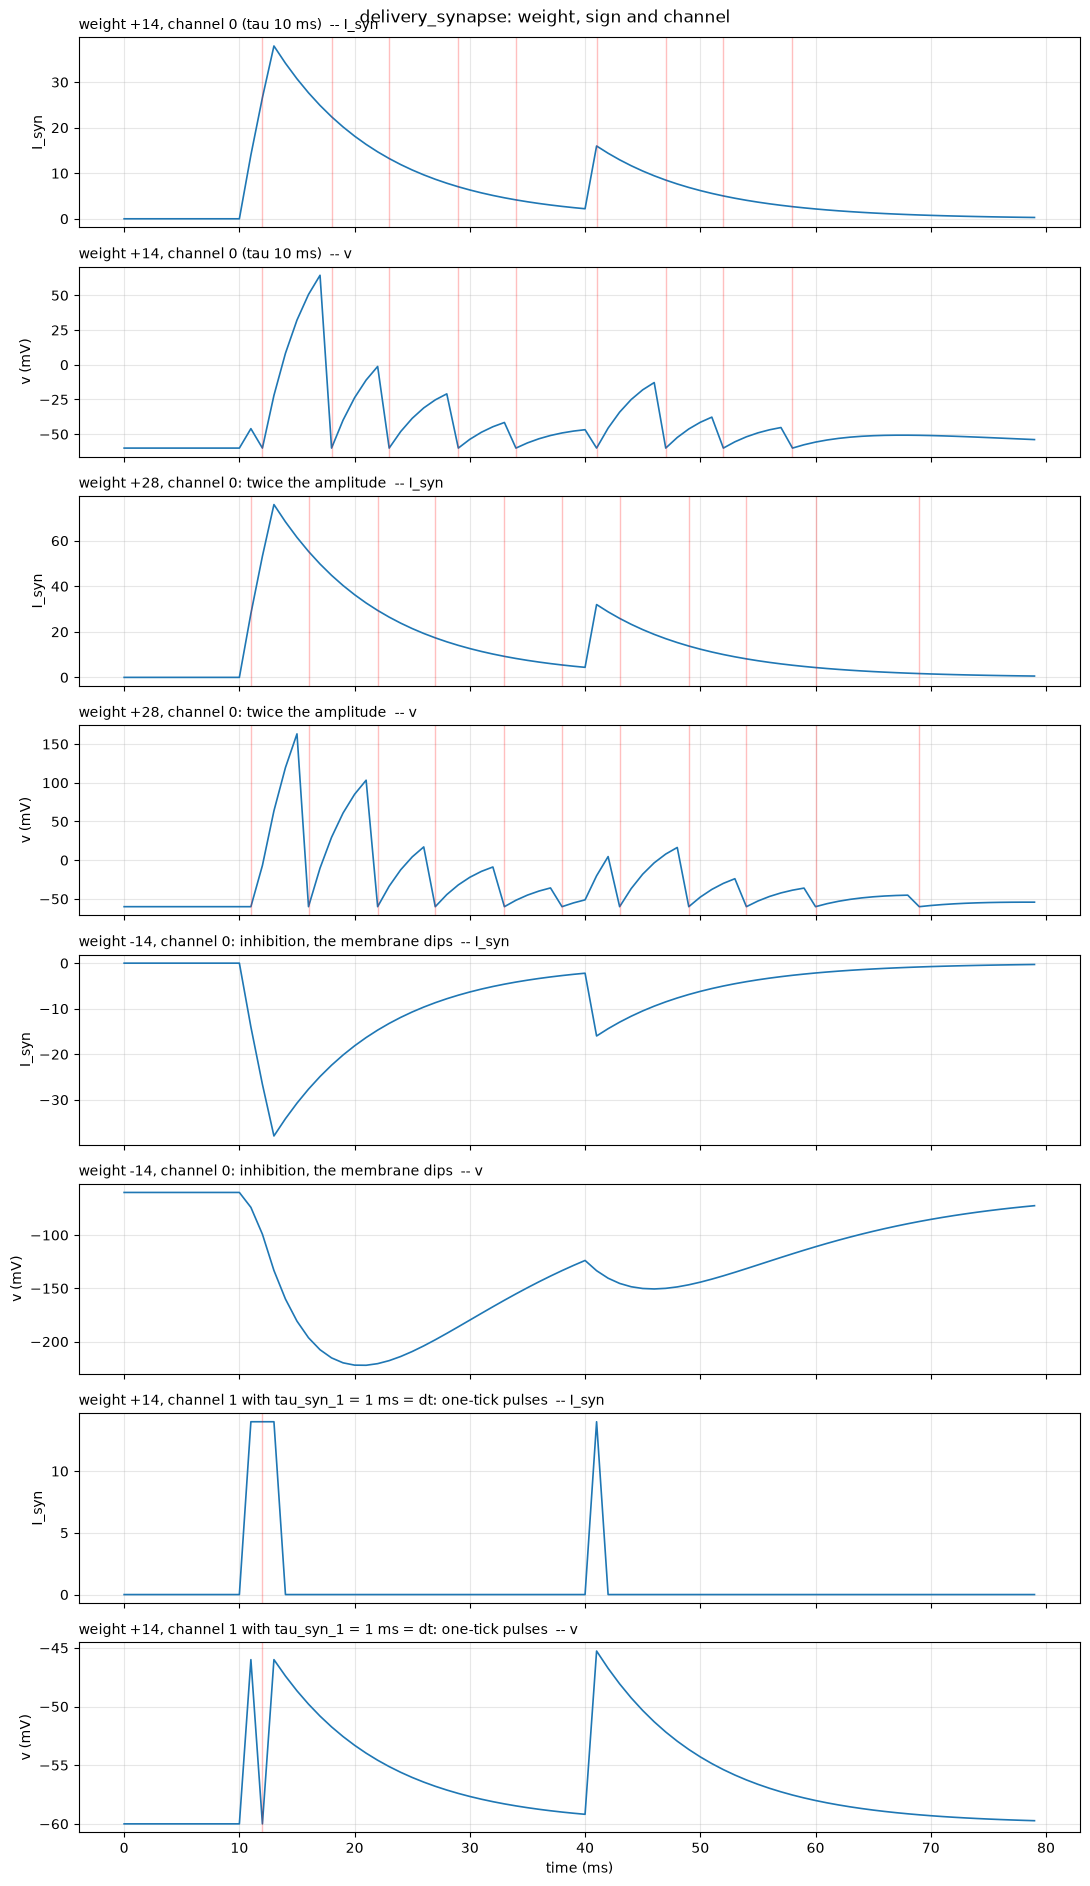

In [9]:
def soma_with_input(weight, channel, tau_syn_1=1e-2, ticks=80, spikes=(10, 11, 12, 40)):
    spikes_out, hist, _ = run_soma(
        "lif_soma", "config_0", ticks=ticks, spikes=list(spikes), weight=weight, channel=channel,
        overrides={"hyperparameters": {"tau_syn_1": tau_syn_1}})
    return spikes_out, hist

cases = [
    ("weight +14, channel 0 (tau 10 ms)",  14.0, 0, 1e-2),
    ("weight +28, channel 0: twice the amplitude",  28.0, 0, 1e-2),
    ("weight -14, channel 0: inhibition, the membrane dips", -14.0, 0, 1e-2),
    ("weight +14, channel 1 with tau_syn_1 = 1 ms = dt: one-tick pulses", 14.0, 1, 1e-3),
]
rows = []
for label, w, ch, tau1 in cases:
    s, hist = soma_with_input(w, ch, tau1)
    rows.append((label + "  -- I_syn", "I_syn", hist[:, 3], s))
    rows.append((label + "  -- v", "v (mV)", hist[:, 0], s))
plot_rows(rows, "delivery_synapse: weight, sign and channel")

Two synapses on **different channels of the same soma** add up: the soma keeps one filtered
current per channel and sums them. That is how one neuron receives inputs with different time
constants (two receptor types, or Cora's 1 ms graph edges next to 5 ms training inputs). The
number of channels is `NeuromorphicModel(synaptic_channels=K)`, default 2; a config must then
carry `tau_syn_0..K-1` and `I_syn_0..K-1`.

summed current at ticks 11, 12, 31, 32: [28.    12.6   15.702  1.532]


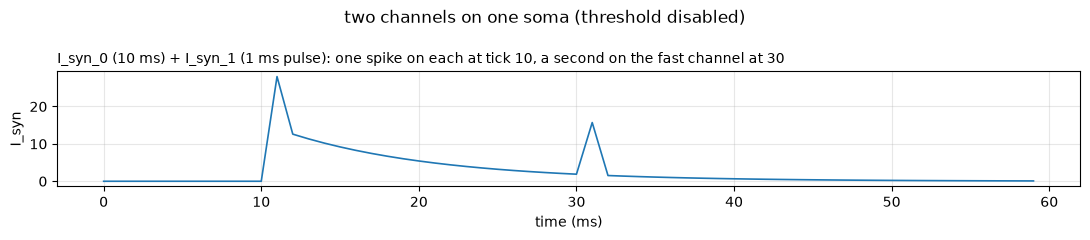

In [10]:
model = NeuromorphicModel(enable_internal_states_tracking=True)
soma = model.create_soma(breed="lif_soma", config_name="config_0",
                         overrides={"hyperparameters": {"tau_syn_0": 1e-2, "tau_syn_1": 1e-3, "vthr": 1e9}})
slow = model.create_synapse(breed="delivery_synapse", pre_soma_id=-1, post_soma_id=soma,
                            config_name="config_0", overrides={"hyperparameters": {"channel": 0}})
fast = model.create_synapse(breed="delivery_synapse", pre_soma_id=-1, post_soma_id=soma,
                            config_name="config_0", overrides={"hyperparameters": {"channel": 1}})
model.setup()
model.add_spike_list(slow, [[10, 1.0]])
model.add_spike_list(fast, [[10, 1.0], [30, 1.0]])
model.simulate(ticks=60)
hist = np.array(model.get_internal_states_history(soma))
# the soma's per-channel states are internal_states[3] and [4]; the history keeps the sum
I_slow = hist[:, 3]
print("summed current at ticks 11, 12, 31, 32:", np.round(I_slow[[11, 12, 31, 32]], 3))
plot_rows([("I_syn_0 (10 ms) + I_syn_1 (1 ms pulse): one spike on each at tick 10, a second on the fast channel at 30",
            "I_syn", I_slow, [])], "two channels on one soma (threshold disabled)")

## 7. Learning rules on one spike pairing

A synapse becomes plastic by naming a `learning_rule`. All six built-in rules are run on the
same tiny circuit: an external synapse drives neuron A, a plastic synapse A→B, and a second
external synapse forces B to fire right after A (causal, pre-before-post) or right before A
(anti-causal). Both drives are one-tick pulses, so A and B fire exactly once per pairing. The table shows
how each rule moved the weight from its initial 14.0 after two pairings.

The rules are stepped only on the ticks their pre or post neuron fires (`synapse_stepping="event"`,
the default) and decay their traces over the ticks in between, so the result is the same as
stepping them every tick.

In [11]:
# learning_rule= names the config BLOCK under learning_rule: in the YAML; the block's
# stdp_type value selects the kernel. Four blocks are named after their kernel, the
# quantized and memristive kernels have their own block names.
RULES = ["exp_pair_wise_stdp", "exp_pair_wise_stdp_bounded", "three_bit_exp_pair_wise_stdp",
         "memristive_exp_pair_wise_stdp", "triplet_stdp", "suppression_stdp"]

def pairing(rule, post_offset):
    """A fires at ~tick 10 and ~tick 40; B is forced at those ticks + post_offset."""
    model = NeuromorphicModel(enable_internal_states_tracking=False)
    # channel 0 as a one-tick pulse (tau_syn_0 = dt): a drive spike of weight 20 moves the
    # membrane by 20 mV once, so each input spike gives exactly one output spike and the
    # plastic synapse (weight 14 -> 14 mV, below threshold) never fires B on its own.
    pulse = {"hyperparameters": {"tau_syn_0": 1e-3}}
    a = model.create_soma(breed="lif_soma", config_name="config_0", overrides=pulse)
    b = model.create_soma(breed="lif_soma", config_name="config_0", overrides=pulse)
    drive_a = model.create_synapse(breed="delivery_synapse", pre_soma_id=-1, post_soma_id=a,
                                   config_name="config_0", overrides={"hyperparameters": {"weight": 20.0}})
    drive_b = model.create_synapse(breed="delivery_synapse", pre_soma_id=-1, post_soma_id=b,
                                   config_name="config_0", overrides={"hyperparameters": {"weight": 20.0}})
    plastic = model.create_synapse(breed="delivery_synapse", pre_soma_id=a, post_soma_id=b,
                                   config_name="config_0", learning_rule=rule, learning_rule_config="default",
                                   overrides={"hyperparameters": {"weight": 14.0}})
    model.setup()
    for t0 in (10, 40):
        model.add_spike(drive_a, tick=t0, value=1.0)
        model.add_spike(drive_b, tick=t0 + post_offset, value=1.0)
    model.simulate(ticks=80)
    w = model.get_hyperparameters(plastic)["weight"]
    return w - 14.0, model.get_spike_times(a), model.get_spike_times(b)

print(f"{'rule':32s} {'post 3 ticks AFTER pre':>24s} {'post 3 ticks BEFORE pre':>25s}")
for rule in RULES:
    causal, sa, sb = pairing(rule, +3)
    anti, _, _ = pairing(rule, -3)
    print(f"{rule:32s} {causal:+24.5f} {anti:+25.5f}")
print("\nA spikes:", sa, " B spikes (causal case):", sb, " -- two clean pairings")

rule                               post 3 ticks AFTER pre   post 3 ticks BEFORE pre


exp_pair_wise_stdp                               +0.00715                  -0.00715


exp_pair_wise_stdp_bounded                       +0.00715                  -0.00715


three_bit_exp_pair_wise_stdp                     -0.28571                  -0.28571


memristive_exp_pair_wise_stdp                    +0.50490                  +0.49841


triplet_stdp                                     +0.02046                  -0.01294


suppression_stdp                                 +0.00419                  -0.00435

A spikes: [11, 41]  B spikes (causal case): [14, 44]  -- two clean pairings


Reading the table:

- the **pair-wise** rules potentiate on pre-before-post and depress on post-before-pre, by amounts
  set by `a_exp_pre`, `a_exp_post` and the trace time constants; `bounded` clips to
  `[wmin, wmax]`, the three-bit block runs the quantized kernel (weight snapped to a grid), the
  memristive block maps the weight through a device conductance model;
- the **triplet** rule adds a term that depends on the previous post spike (`o2`), so a second
  pairing counts more than the first;
- the **suppression** rule scales each spike's efficacy by how long it has been since the same
  neuron's previous spike (`tau_supp_*`), so closely spaced spikes count less.
- two rows do not flip sign with the pairing order, and that is the rule, not a bug: the
  **three-bit** block snaps the weight to its 8-level grid between `wmin` and `wmax` first, and
  14.0 is not on that grid, so the −0.29 in both columns is the quantisation step; the
  **memristive** block maps the weight through a device conductance with its default
  programming parameters, and at this weight the device's write step dominates the direction
  term. Both are tuned per experiment through their `default` block.

## 8. Where to look next

| breed / rule | configs | kernel |
|---|---|---|
| `lif_soma` | `config_0` | `superneuroabm/step_functions/soma/lif.py` |
| `lif_soma_adaptive_thr` | `config_0` | `soma/lif_soma_adaptive_thr.py` |
| `izh_soma` | `config_0` … `config_19` (figure 1 A–T) | `soma/izh.py` |
| `adex_soma` | `config_0` … `config_6` (table 6.1) | `soma/adex.py` |
| `hg_lif_soma` | `config_0` | `soma/hg_lif.py` |
| `delivery_synapse` | `config_0` (weight 14), `config_1` (weight 100) | `synapse/delivery.py` |
| six learning rules | `default` | `synapse/stdp/*.py` |

Every kernel is a plain CUDA function with the same signature; tutorial 01 shows how to write
your own soma and rule next to a notebook and register them, and `docs/FUNCTIONALITY_GUIDE.md`
has the equations and parameter tables.